# BrushCue Example: Oil Painting Effect

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/oil_painting_effect.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/oil-painting-effect

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


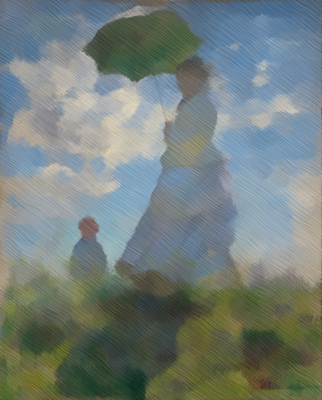

In [1]:
import io
from PIL import Image

import brushcue as bc

brush_size = 18.0
brush_texture = 0.55
effect_strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
reference_scale = (
    bc.Float.max(1.0, bc.Float.min(bounds.width(), bounds.height())) / 1000.0
)
radius = bc.Float.max(1.0, (brush_size * reference_scale))
painted = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet p = clamp(position, lo, hi);\nlet center = sample(p);\nlet uv = (p - image_bounds.xy) / reference_scale;\nlet jitter = vec2f(noise(uv / 19.0), noise(uv / 19.0 + vec2f(37.0, 13.0))) - vec2f(0.5);\nlet origin = p + jitter * radius * 0.12;\nlet east = sample(clamp(p + vec2f(radius, 0.0), lo, hi));\nlet west = sample(clamp(p - vec2f(radius, 0.0), lo, hi));\nlet south = sample(clamp(p + vec2f(0.0, radius), lo, hi));\nlet north = sample(clamp(p - vec2f(0.0, radius), lo, hi));\nlet gradient = vec2f((east.r - west.r) * min(east.a, west.a), (south.r - north.r) * min(south.a, north.a));\nlet tangent = select(vec2f(0.8, 0.6), vec2f(-gradient.y, gradient.x) / max(length(gradient), 0.0001), length(gradient) > 0.015);\nlet normal = vec2f(-tangent.y, tangent.x);\nvar sums: array<vec3f, 4>;\nvar squares: array<vec3f, 4>;\nvar counts: array<f32, 4>;\nfor (var y = -3; y <= 3; y = y + 1) {\n    for (var x = -3; x <= 3; x = x + 1) {\n        let q = clamp(origin + (tangent * f32(x) * 1.5 + normal * f32(y) * 0.75) * radius / 3.0, lo, hi);\n        let c = sample(q);\n        for (var k = 0; k < 4; k = k + 1) {\n            let in_x = select(x >= 0, x <= 0, (k % 2) == 0);\n            let in_y = select(y >= 0, y <= 0, k < 2);\n            if (in_x && in_y) {\n                sums[k] += c.rgb * c.a;\n                squares[k] += c.rgb * c.rgb * c.a;\n                counts[k] += c.a;\n            }\n        }\n    }\n}\nvar means: array<vec3f, 4>;\nvar variances: array<f32, 4>;\nvar min_variance = 1e6;\nfor (var k = 0; k < 4; k = k + 1) {\n    means[k] = sums[k] / max(counts[k], 0.0001);\n    let variance = max(squares[k] / max(counts[k], 0.0001) - means[k] * means[k], vec3f(0.0));\n    variances[k] = dot(variance, vec3f(1.0, 0.25, 0.25));\n    if (counts[k] > 0.0001) { min_variance = min(min_variance, variances[k]); }\n}\nvar color = vec3f(0.0);\nvar total_weight = 0.0;\nfor (var k = 0; k < 4; k = k + 1) {\n    let ratio = (min_variance + 0.0001) / (variances[k] + 0.0001);\n    let weight = select(0.0, pow(clamp(ratio, 0.0, 1.0), 12.0), counts[k] > 0.0001);\n    color += means[k] * weight;\n    total_weight += weight;\n}\nlet wash = select(center.rgb, color / max(total_weight, 0.0001), total_weight > 0.0001);\nreturn vec4f(mix(center.rgb, wash, effect_strength), center.a);",
    "fn hash(p: vec2f) -> f32 {\n    let q = fract(p * vec2f(0.1031, 0.11369));\n    let n = dot(q, q.yx + vec2f(19.19));\n    return fract((q.x + q.y + n) * (q.x + n));\n}\nfn noise(p: vec2f) -> f32 {\n    let i = floor(p);\n    let f = fract(p);\n    let u = f * f * (vec2f(3.0) - 2.0 * f);\n    return mix(mix(hash(i), hash(i + vec2f(1.0, 0.0)), u.x),\n        mix(hash(i + vec2f(0.0, 1.0)), hash(i + vec2f(1.0)), u.x), u.y);\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("reference_scale", reference_scale)
    .add("radius", radius)
    .add("effect_strength", effect_strength),
    bc.ColorRepresentation.oklab_a(),
).crop(bounds)
graph = painted.spacial_effect_shader(
    "let p = clamp(position, image_bounds.xy + vec2f(0.5), image_bounds.zw - vec2f(0.5));\nlet c = sample(p);\nlet uv = (p - image_bounds.xy) / max(reference_scale, 0.0001);\n// Stretched noise forms bristle ridges; coarse variation breaks up their direction.\nlet bend = (noise(uv / 65.0) - 0.5) * 12.0;\nlet along = dot(uv, vec2f(0.8, 0.6));\nlet across = dot(uv, vec2f(-0.6, 0.8)) + bend;\nlet stroke = vec2f(along / max(brush_size * 3.0, 1.0), across / 2.2);\nlet relief = noise(stroke + vec2f(0.0, 0.25)) - noise(stroke - vec2f(0.0, 0.25));\nlet canvas = (noise(uv * 0.8) - 0.5) * 0.025;\nlet rgb = clamp(c.rgb, vec3f(0.0), vec3f(1.0));\nlet lightness = dot(rgb, vec3f(0.2126, 0.7152, 0.0722));\n// Midtones carry the relief, while black and white retain their endpoints.\nlet shading = (relief * 0.35 + canvas) * brush_texture * effect_strength;\nlet result = rgb + vec3f(shading * 4.0 * lightness * (1.0 - lightness));\nreturn vec4f(clamp(result, vec3f(0.0), vec3f(1.0)), c.a);",
    "fn hash(p: vec2f) -> f32 {\n    let q = fract(p * vec2f(0.1031, 0.11369));\n    let n = dot(q, q.yx + vec2f(19.19));\n    return fract((q.x + q.y + n) * (q.x + n));\n}\nfn noise(p: vec2f) -> f32 {\n    let i = floor(p);\n    let f = fract(p);\n    let u = f * f * (vec2f(3.0) - 2.0 * f);\n    return mix(mix(hash(i), hash(i + vec2f(1.0, 0.0)), u.x),\n        mix(hash(i + vec2f(0.0, 1.0)), hash(i + vec2f(1.0)), u.x), u.y);\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("reference_scale", reference_scale)
    .add("brush_size", brush_size)
    .add("brush_texture", brush_texture)
    .add("effect_strength", effect_strength),
    bc.ColorRepresentation.srgb(),
).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
